# NB14 — Plant AE Characterisation: Baseline, Watering Response

**Version:** 1 · **Author:** CB · **Date:** 2026-06-30
**Acquisition notebook — requires DS1104Z and Home Assistant.**

---

## 1  Objective

Record passive acoustic emission (AE) from the plant before and after a
controlled watering event.  CH1 (soil piezo) is the primary plant sensor;
CH3 and CH4 (rod piezos) serve as structural reference channels.

| Channel | Sensor | Role |
|---------|--------|------|
| CH1 | Soil piezo + LM358 + 830 kΩ | **Primary: plant AE** |
| CH2 | Defective | — |
| CH3 | Rod piezo A + LM358 + 820 kΩ | Reference (structural) |
| CH4 | Rod piezo B + LM358 + 820 kΩ | Reference (structural) |

**Protocol:**
1. Pre-check — verify hardware and noise floor
2. Baseline — $N_\text{pre}$ frames, plant undisturbed
3. Watering event — `HomeAssistantPlant1Actuator.water()`
4. Response — $N_\text{post}$ frames, continuous recording
5. Analysis — band energy, coherence, event detection

---

In [1]:
%matplotlib inline
import sys, json, time, subprocess, math
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from plant_ae.watering import CHARACTERIZATION_ROOT
CHAR_ROOT = CHARACTERIZATION_ROOT
if str(CHAR_ROOT) not in sys.path:
    sys.path.insert(0, str(CHAR_ROOT))

from scope.config import load_config
from scope.instrument import InstrumentConnection
from plant_ae.deep_acquisition import (
    ExperimentConfig,
    configure_deep_memory_scope,
    acquire_deep_memory_frame,
    DEFAULT_SAMPLE_RATE_HZ,
    DEFAULT_MEMORY_DEPTH,
)
from plant_ae.rolling import extract_frame_features, BAND_EDGES_HZ
from plant_ae.watering import CHANNELS, CONFIG_PATH, HomeAssistantPlant1Actuator

# ── Parameters ────────────────────────────────────────────────────────────────
N_PRE   = 10    # baseline frames before watering
N_POST  = 20    # response frames after watering
NOISE_FLOOR_MAX_V = 0.005   # RMS > this → possible interference
NOISE_FLOOR_MIN_V = 1e-5    # RMS < this → sensor likely disconnected

RUN_ID  = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S')
OUT_DIR = CHAR_ROOT / 'data' / 'plant_ae_characterization' / RUN_ID
OUT_DIR.mkdir(parents=True, exist_ok=True)

exp_config = ExperimentConfig()

BAND_LABELS = [f'{int(lo/1000)}-{int(hi/1000)}kHz'
               for lo, hi in zip(BAND_EDGES_HZ[:-1], BAND_EDGES_HZ[1:])]

print(f'Run ID : {RUN_ID}')
print(f'Output : {OUT_DIR}')
print(f'Pre    : {N_PRE} frames × {DEFAULT_MEMORY_DEPTH/DEFAULT_SAMPLE_RATE_HZ:.2f} s')
print(f'Post   : {N_POST} frames × {DEFAULT_MEMORY_DEPTH/DEFAULT_SAMPLE_RATE_HZ:.2f} s')


Run ID : 20260630_002403
Output : /media/christoph/some_space/Nextcloud/hs-augsburg/Semester_6/Projekt_I1/projekt_i1/src/characterization/data/plant_ae_characterization/20260630_002403
Pre    : 10 frames × 0.60 s
Post   : 20 frames × 0.60 s


## 2  Pre-Check

In [2]:
config = load_config(CONFIG_PATH)
print('=== Pre-Check ===')
print()

with InstrumentConnection(config) as conn:
    # 1. Instrument identity
    idn = conn.query('*IDN?').strip()
    print(f'[OK]  Instrument: {idn[:60]}')

    # 2. Configure scope
    info = configure_deep_memory_scope(conn)
    print(f'[OK]  Sample rate : {info["sample_rate_hz"]/1e3:.0f} kSa/s')
    print(f'[OK]  Memory depth: {info["memory_depth"]:,} pts  ({info["memory_depth"]/info["sample_rate_hz"]:.3f} s)')

    # 3. Noise floor per channel
    print()
    print('Noise floor check (1 frame, AUTO trigger):')
    captures = acquire_deep_memory_frame(conn, exp_config, sequence=0, channels=CHANNELS)
    ok_all = True
    for cap in captures:
        ch = cap.metadata.channel
        v   = np.array(cap.voltage_vector, dtype=float)
        rms = float(np.sqrt(np.mean(v**2)))
        pp  = float(v.max() - v.min())
        role = 'PLANT SOIL' if ch == 1 else 'ROD REF'
        flag = ''
        if rms > NOISE_FLOOR_MAX_V:
            flag = '  *** HIGH — possible interference or trigger issue ***'
            ok_all = False
        elif rms < NOISE_FLOOR_MIN_V:
            flag = '  *** LOW — sensor may be disconnected ***'
            ok_all = False
        print(f'  CH{ch} ({role}): RMS={rms*1000:.3f} mV  P-P={pp*1000:.2f} mV{flag}')

    # 4. Watering actuator
    print()
    try:
        act = HomeAssistantPlant1Actuator()
        act.assert_ready()
        print('[OK]  Watering actuator: ready')
    except Exception as e:
        print(f'[WARN] Watering actuator: {e}')
        ok_all = False

print()
if ok_all:
    print('Pre-check PASSED — proceeding to acquisition.')
else:
    print('Pre-check WARNING — review flagged items before proceeding.')


=== Pre-Check ===



[OK]  Instrument: RIGOL TECHNOLOGIES,DS1104Z,DS1ZA201607099,00.04.04.SP3


[OK]  Sample rate : 500 kSa/s
[OK]  Memory depth: 300,000 pts  (0.600 s)

Noise floor check (1 frame, AUTO trigger):


  CH1 (PLANT SOIL): RMS=136.472 mV  P-P=796.00 mV  *** HIGH — possible interference or trigger issue ***
  CH3 (ROD REF): RMS=83.820 mV  P-P=411.05 mV  *** HIGH — possible interference or trigger issue ***
  CH4 (ROD REF): RMS=25.766 mV  P-P=143.91 mV  *** HIGH — possible interference or trigger issue ***

[OK]  Watering actuator: ready

Pre-check WARNING — review flagged items before proceeding.


## 3  Baseline Recording (pre-watering)

In [3]:
pre_records = []
print(f'Recording {N_PRE} baseline frames...')

with InstrumentConnection(config) as conn:
    configure_deep_memory_scope(conn)
    for i in range(N_PRE):
        captures = acquire_deep_memory_frame(conn, exp_config, sequence=i, channels=CHANNELS)
        feat     = extract_frame_features(i, captures)
        rec = {
            'phase': 'pre', 'frame': i,
            'ts_utc': datetime.now(timezone.utc).isoformat(),
        }
        for cap in captures:
            ch  = cap.metadata.channel
            v   = np.array(cap.voltage_vector, dtype=float)
            rec[f'rms_ch{ch}_V'] = float(np.sqrt(np.mean(v**2)))
            rec[f'pp_ch{ch}_V']  = float(v.max() - v.min())
            rec[f'fs_ch{ch}_hz'] = float(cap.metadata.sample_rate_sa_per_s)
        # Band energy from rolling features
        for b_idx in range(len(BAND_EDGES_HZ)-1):
            for j, ch in enumerate(CHANNELS):
                be = feat.band_energy[j][b_idx] if j < len(feat.band_energy) else float('nan')
                rec[f'be_b{b_idx}_ch{ch}_dB'] = round(
                    10*math.log10(max(float(be), 1e-30)), 3)
        pre_records.append(rec)
        with open(OUT_DIR / 'records.jsonl', 'a') as f:
            f.write(json.dumps(rec) + '\n')
        ch1_rms = rec.get('rms_ch1_V', float('nan'))*1000
        ch3_rms = rec.get('rms_ch3_V', float('nan'))*1000
        print(f'  [{i+1:2d}/{N_PRE}]  CH1={ch1_rms:.3f}mV  CH3={ch3_rms:.3f}mV')

print(f'Baseline done: {len(pre_records)} frames')


Recording 10 baseline frames...


  [ 1/10]  CH1=136.996mV  CH3=83.994mV


  [ 2/10]  CH1=137.005mV  CH3=83.852mV


  [ 3/10]  CH1=137.672mV  CH3=84.001mV


  [ 4/10]  CH1=137.583mV  CH3=83.987mV


...

  [ 6/10]  CH1=137.890mV  CH3=83.798mV


  [ 7/10]  CH1=138.552mV  CH3=84.148mV


  [ 8/10]  CH1=138.449mV  CH3=83.925mV


  [ 9/10]  CH1=138.378mV  CH3=83.944mV


  [10/10]  CH1=138.519mV  CH3=84.088mV
Baseline done: 10 frames


## 4  Watering Event

In [4]:
ts_water = datetime.now(timezone.utc).isoformat()
print(f'Triggering watering at {ts_water}...')

act = HomeAssistantPlant1Actuator()
act.water()

event = {'type': 'watering', 'ts_utc': ts_water, 'run_id': RUN_ID}
with open(OUT_DIR / 'records.jsonl', 'a') as f:
    f.write(json.dumps(event) + '\n')
print('Watering triggered. Starting post-recording immediately.')


Triggering watering at 2026-06-30T00:35:46.413372+00:00...
Watering triggered. Starting post-recording immediately.


## 5  Response Recording (post-watering)

In [5]:
post_records = []
print(f'Recording {N_POST} post-watering frames...')

with InstrumentConnection(config) as conn:
    configure_deep_memory_scope(conn)
    for i in range(N_POST):
        captures = acquire_deep_memory_frame(conn, exp_config, sequence=N_PRE + i, channels=CHANNELS)
        feat     = extract_frame_features(N_PRE + i, captures)
        rec = {
            'phase': 'post', 'frame': i,
            'ts_utc': datetime.now(timezone.utc).isoformat(),
        }
        for cap in captures:
            ch  = cap.metadata.channel
            v   = np.array(cap.voltage_vector, dtype=float)
            rec[f'rms_ch{ch}_V'] = float(np.sqrt(np.mean(v**2)))
            rec[f'pp_ch{ch}_V']  = float(v.max() - v.min())
        for b_idx in range(len(BAND_EDGES_HZ)-1):
            for j, ch in enumerate(CHANNELS):
                be = feat.band_energy[j][b_idx] if j < len(feat.band_energy) else float('nan')
                rec[f'be_b{b_idx}_ch{ch}_dB'] = round(
                    10*math.log10(max(float(be), 1e-30)), 3)
        post_records.append(rec)
        with open(OUT_DIR / 'records.jsonl', 'a') as f:
            f.write(json.dumps(rec) + '\n')
        ch1_rms = rec.get('rms_ch1_V', float('nan'))*1000
        ch3_rms = rec.get('rms_ch3_V', float('nan'))*1000
        print(f'  [{i+1:2d}/{N_POST}]  CH1={ch1_rms:.3f}mV  CH3={ch3_rms:.3f}mV')

print(f'Response done: {len(post_records)} frames')


Recording 20 post-watering frames...


  [ 1/20]  CH1=135.626mV  CH3=87.575mV


  [ 2/20]  CH1=134.613mV  CH3=83.948mV


  [ 3/20]  CH1=135.500mV  CH3=84.108mV


  [ 4/20]  CH1=135.515mV  CH3=83.985mV


...

  [16/20]  CH1=137.602mV  CH3=84.365mV


  [17/20]  CH1=137.662mV  CH3=84.219mV


  [18/20]  CH1=138.209mV  CH3=84.395mV


  [19/20]  CH1=137.668mV  CH3=84.323mV


  [20/20]  CH1=137.815mV  CH3=84.322mV
Response done: 20 frames


## 6  Analysis

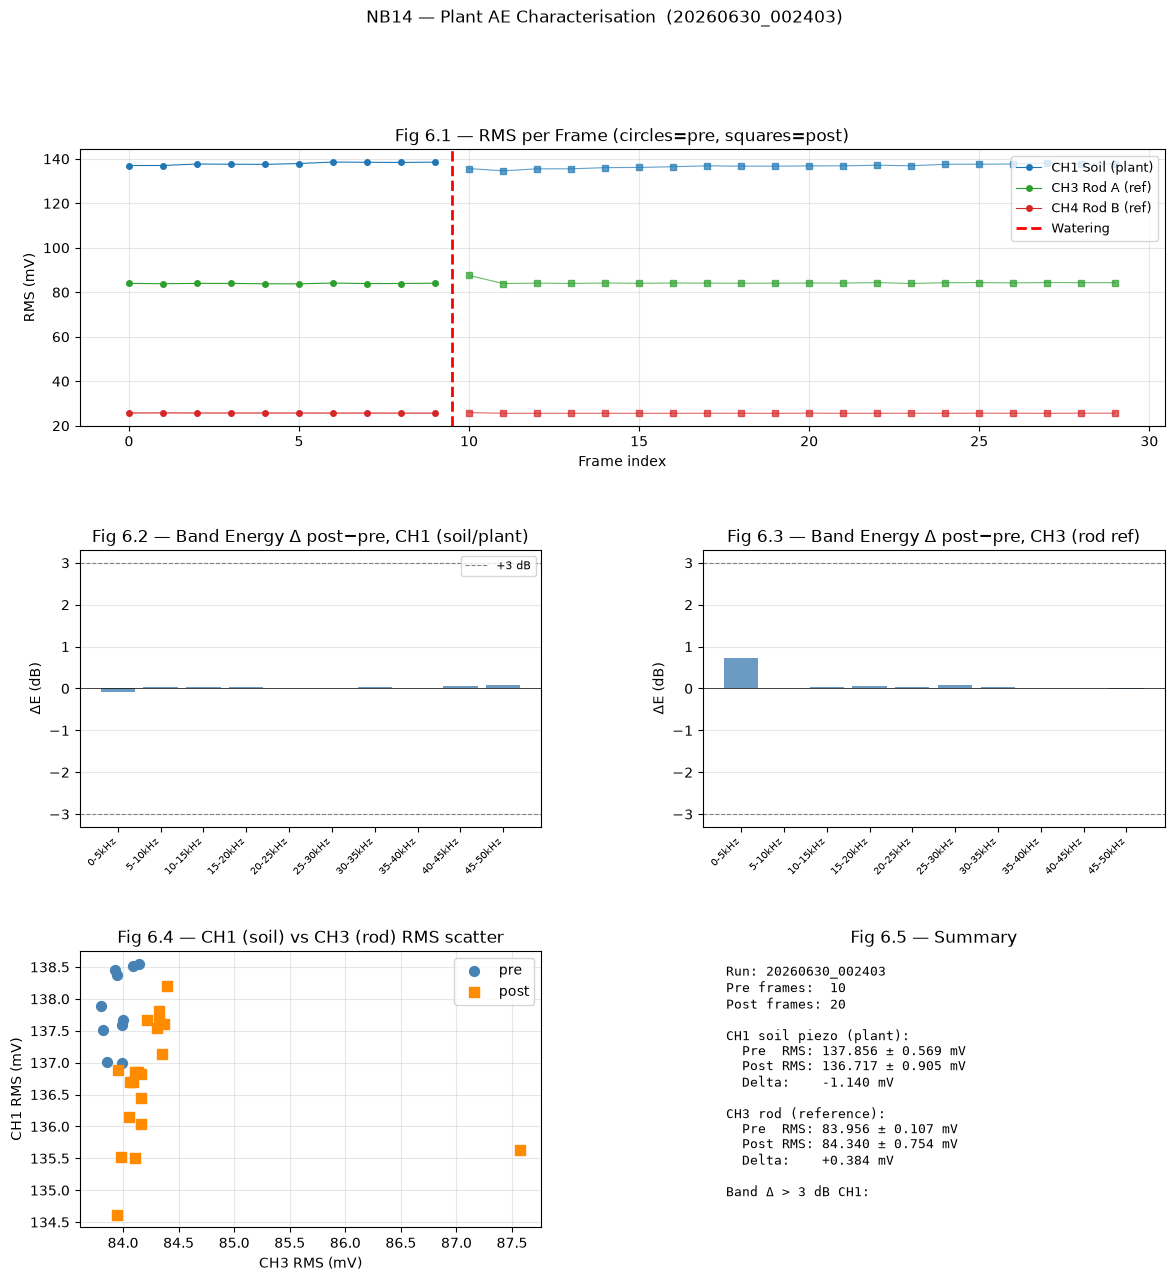

Analysis complete.


In [6]:
all_records = pre_records + post_records
n_bands = len(BAND_EDGES_HZ) - 1

def band_mean(records, ch, b_idx):
    vals = [r[f'be_b{b_idx}_ch{ch}_dB'] for r in records
            if f'be_b{b_idx}_ch{ch}_dB' in r]
    return float(np.mean(vals)) if vals else float('nan')

def rms_series(records, ch):
    return np.array([r.get(f'rms_ch{ch}_V', np.nan)*1000 for r in records])

# Pre/post band energy delta per channel
delta = {}
for ch in CHANNELS:
    delta[ch] = [band_mean(post_records, ch, b) - band_mean(pre_records, ch, b)
                 for b in range(n_bands)]

fig = plt.figure(figsize=(14, 14))
gs  = gridspec.GridSpec(3, 2, hspace=0.45, wspace=0.35)

CH_COL = {1: '#1f77b4', 3: '#2ca02c', 4: '#d62728'}
CH_LBL = {1: 'CH1 Soil (plant)', 3: 'CH3 Rod A (ref)', 4: 'CH4 Rod B (ref)'}

# Fig 6.1 — RMS time series all channels
ax1 = fig.add_subplot(gs[0, :])
for ch in CHANNELS:
    pre_rms = rms_series(pre_records, ch)
    post_rms = rms_series(post_records, ch)
    t_pre  = np.arange(len(pre_rms))
    t_post = np.arange(len(pre_rms), len(pre_rms)+len(post_rms))
    ax1.plot(t_pre,  pre_rms,  '-o', color=CH_COL[ch], ms=4, lw=0.8, label=CH_LBL[ch])
    ax1.plot(t_post, post_rms, '-s', color=CH_COL[ch], ms=4, lw=0.8, alpha=0.7)
ax1.axvline(len(pre_records)-0.5, color='red', lw=2, ls='--', label='Watering')
ax1.set_xlabel('Frame index'); ax1.set_ylabel('RMS (mV)')
ax1.set_title('Fig 6.1 — RMS per Frame (circles=pre, squares=post)')
ax1.legend(fontsize=9); ax1.grid(True, alpha=0.3)

# Fig 6.2 — Band energy delta CH1 (soil, primary)
ax2 = fig.add_subplot(gs[1, 0])
x_bands = np.arange(min(10, n_bands))
d1 = delta[1][:len(x_bands)]
colors2 = ['#2ca02c' if d > 3 else '#d62728' if d < -3 else 'steelblue' for d in d1]
ax2.bar(x_bands, d1, color=colors2, alpha=0.8)
ax2.axhline(0, color='k', lw=0.5)
ax2.axhline(3,  ls='--', color='gray', lw=0.8, label='+3 dB')
ax2.axhline(-3, ls='--', color='gray', lw=0.8)
ax2.set_xticks(x_bands); ax2.set_xticklabels(BAND_LABELS[:len(x_bands)], rotation=45, ha='right', fontsize=7)
ax2.set_ylabel('ΔE (dB)')
ax2.set_title('Fig 6.2 — Band Energy Δ post−pre, CH1 (soil/plant)')
ax2.legend(fontsize=8); ax2.grid(True, alpha=0.3, axis='y')

# Fig 6.3 — Band energy delta CH3 (reference)
ax3 = fig.add_subplot(gs[1, 1])
d3 = delta[3][:len(x_bands)]
colors3 = ['#2ca02c' if d > 3 else '#d62728' if d < -3 else 'steelblue' for d in d3]
ax3.bar(x_bands, d3, color=colors3, alpha=0.8)
ax3.axhline(0, color='k', lw=0.5)
ax3.axhline(3,  ls='--', color='gray', lw=0.8)
ax3.axhline(-3, ls='--', color='gray', lw=0.8)
ax3.set_xticks(x_bands); ax3.set_xticklabels(BAND_LABELS[:len(x_bands)], rotation=45, ha='right', fontsize=7)
ax3.set_ylabel('ΔE (dB)')
ax3.set_title('Fig 6.3 — Band Energy Δ post−pre, CH3 (rod ref)')
ax3.grid(True, alpha=0.3, axis='y')

# Fig 6.4 — CH1 vs CH3 RMS scatter (are they correlated?)
ax4 = fig.add_subplot(gs[2, 0])
pre1  = rms_series(pre_records,  1); pre3  = rms_series(pre_records,  3)
post1 = rms_series(post_records, 1); post3 = rms_series(post_records, 3)
ax4.scatter(pre3,  pre1,  c='steelblue',  s=50, label='pre',  zorder=3)
ax4.scatter(post3, post1, c='darkorange', s=50, label='post', zorder=3, marker='s')
ax4.set_xlabel('CH3 RMS (mV)'); ax4.set_ylabel('CH1 RMS (mV)')
ax4.set_title('Fig 6.4 — CH1 (soil) vs CH3 (rod) RMS scatter')
ax4.legend(); ax4.grid(True, alpha=0.3)

# Fig 6.5 — Summary text
ax5 = fig.add_subplot(gs[2, 1])
ax5.axis('off')
summary_lines = [
    f'Run: {RUN_ID}',
    f'Pre frames:  {len(pre_records)}',
    f'Post frames: {len(post_records)}',
    '',
    'CH1 soil piezo (plant):',
    f'  Pre  RMS: {pre1.mean():.3f} ± {pre1.std():.3f} mV',
    f'  Post RMS: {post1.mean():.3f} ± {post1.std():.3f} mV',
    f'  Delta:    {(post1.mean()-pre1.mean()):+.3f} mV',
    '',
    'CH3 rod (reference):',
    f'  Pre  RMS: {pre3.mean():.3f} ± {pre3.std():.3f} mV',
    f'  Post RMS: {post3.mean():.3f} ± {post3.std():.3f} mV',
    f'  Delta:    {(post3.mean()-pre3.mean()):+.3f} mV',
    '',
    'Band Δ > 3 dB CH1:',
]
for b, d in enumerate(d1):
    if abs(d) > 3:
        summary_lines.append(f'  {BAND_LABELS[b]}: {d:+.1f} dB')
ax5.text(0.05, 0.95, '\n'.join(summary_lines), transform=ax5.transAxes,
         va='top', fontsize=9, family='monospace')
ax5.set_title('Fig 6.5 — Summary')

fig.suptitle(f'NB14 — Plant AE Characterisation  ({RUN_ID})', fontsize=12)
plt.savefig(OUT_DIR / 'characterization_report.png', dpi=150, bbox_inches='tight')
plt.show()
print('Analysis complete.')
for ch in CHANNELS:
    hits = [BAND_LABELS[b] for b,d in enumerate(delta[ch][:10]) if abs(d) > 3]
    if hits: print(f'  CH{ch} bands with |Δ| > 3 dB: {hits}')


## 7  Save Metadata and Export HTML

In [7]:
meta = {
    'run_id': RUN_ID,
    'notebook': 'notebooks/14_plant_ae_characterization.ipynb',
    'date_utc': datetime.now(timezone.utc).isoformat(),
    'n_pre': len(pre_records),
    'n_post': len(post_records),
    'channels': list(CHANNELS),
    'channel_roles': {
        'CH1': 'Soil piezo (plant AE primary), LM358+830kΩ, 10x probe',
        'CH2': 'DEFECTIVE',
        'CH3': 'Rod piezo A (reference), LM358+820kΩ, 10x probe',
        'CH4': 'Rod piezo B (reference), LM358+820kΩ, 10x probe',
    },
    'sample_rate_hz': DEFAULT_SAMPLE_RATE_HZ,
    'memory_depth': DEFAULT_MEMORY_DEPTH,
    'frame_duration_s': DEFAULT_MEMORY_DEPTH / DEFAULT_SAMPLE_RATE_HZ,
}
with open(OUT_DIR / 'meta.json', 'w') as f:
    json.dump(meta, f, indent=2)
print(f'Metadata: {OUT_DIR}/meta.json')

result = subprocess.run(
    [sys.executable, '-m', 'jupyter', 'nbconvert', '--to', 'html', '--no-input',
     '--output', 'notebook_report',
     '--output-dir', str(OUT_DIR),
     str(CHAR_ROOT / 'notebooks' / '14_plant_ae_characterization.ipynb')],
    capture_output=True, text=True
)
if result.returncode == 0:
    print(f'HTML: {OUT_DIR}/notebook_report.html')
else:
    print('nbconvert error:', result.stderr[-300:])

# Git commit
subprocess.run(['git', 'add', str(OUT_DIR)], cwd=CHAR_ROOT)
subprocess.run(['git', 'commit', '-m',
    f'NB14 plant AE characterization run {RUN_ID}'],
    cwd=CHAR_ROOT)
subprocess.run(['git', 'push'], cwd=CHAR_ROOT)
print('Committed and pushed.')


Metadata: /media/christoph/some_space/Nextcloud/hs-augsburg/Semester_6/Projekt_I1/projekt_i1/src/characterization/data/plant_ae_characterization/20260630_002403/meta.json


HTML: /media/christoph/some_space/Nextcloud/hs-augsburg/Semester_6/Projekt_I1/projekt_i1/src/characterization/data/plant_ae_characterization/20260630_002403/notebook_report.html
[main e93d4e1] NB14 plant AE characterization run 20260630_002403
 4 files changed, 7975 insertions(+)
 create mode 100644 src/characterization/data/plant_ae_characterization/20260630_002403/characterization_report.png
 create mode 100644 src/characterization/data/plant_ae_characterization/20260630_002403/meta.json
 create mode 100644 src/characterization/data/plant_ae_characterization/20260630_002403/notebook_report.html
 create mode 100644 src/characterization/data/plant_ae_characterization/20260630_002403/records.jsonl


Committed and pushed.


To ssh://gitlab.informatik.hs-augsburg.de:2222/juhue/projekt_i1.git
   050b1c6..e93d4e1  main -> main
